| Item      | Content                                      | Status                               |
| --------- | -------------------------------------------- | ------------------------------------ |
| Table I   | Dataset split and class distribution         | Available                            |
| Table II  | Model architectures and parameter counts     | Needs consolidation                  |
| Table III | Overall test metrics                         | Ready                                |
| Fig. 1    | Experimental pipeline                        | To create                            |
| Fig. 2    | Training/validation macro-F1 and loss curves | Collect from logs                    |
| Fig. 3    | Confusion matrices                           | Available from evaluation outputs    |
| Fig. 4    | Per-class F1 comparison                      | Generate from classification reports |
| Fig. 5    | Grad-CAM / ViT attention examples            | Optional but valuable                |
| Table IV  | Pretrained versus scratch EfficientNet       | Pending                              |
| Table V   | Training and inference cost comparison       | Partially ready                      |

In [7]:
from preprocessing import data_loaders
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from funcs import PROJECT_DIR, CHECKPOINT_DIR

plt.style.use('seaborn-v0_8-paper')
plt.rcParams["savefig.transparent"] = True
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.format"] = 'svg'

In [2]:
data = data_loaders()
train_df, val_df, test_df = [ds.df for ds in data['datasets']]

In [3]:
names = ['train', 'test', 'val']
for name, df in zip(names, [train_df, val_df, test_df]):
    df['split'] = name
df = pd.concat([train_df, val_df, test_df]).drop('path', axis=1)
classes = list(df['class_name'].unique())

### Dataset split and class distribution 

In [4]:
print(df.groupby('split').sum()['label'].to_markdown())
print("\n", df.groupby(['split','class_name']).count())

| split   |   label |
|:--------|--------:|
| test    |    4200 |
| train   |   19600 |
| val     |    4200 |

                               label
split class_name                   
test  dyed-lifted-polyps        150
      dyed-resection-margins    150
      esophagitis               150
      normal-cecum              150
      normal-pylorus            150
      normal-z-line             150
      polyps                    150
      ulcerative-colitis        150
train dyed-lifted-polyps        700
      dyed-resection-margins    700
      esophagitis               700
      normal-cecum              700
      normal-pylorus            700
      normal-z-line             700
      polyps                    700
      ulcerative-colitis        700
val   dyed-lifted-polyps        150
      dyed-resection-margins    150
      esophagitis               150
      normal-cecum              150
      normal-pylorus            150
      normal-z-line             150
      polyps            

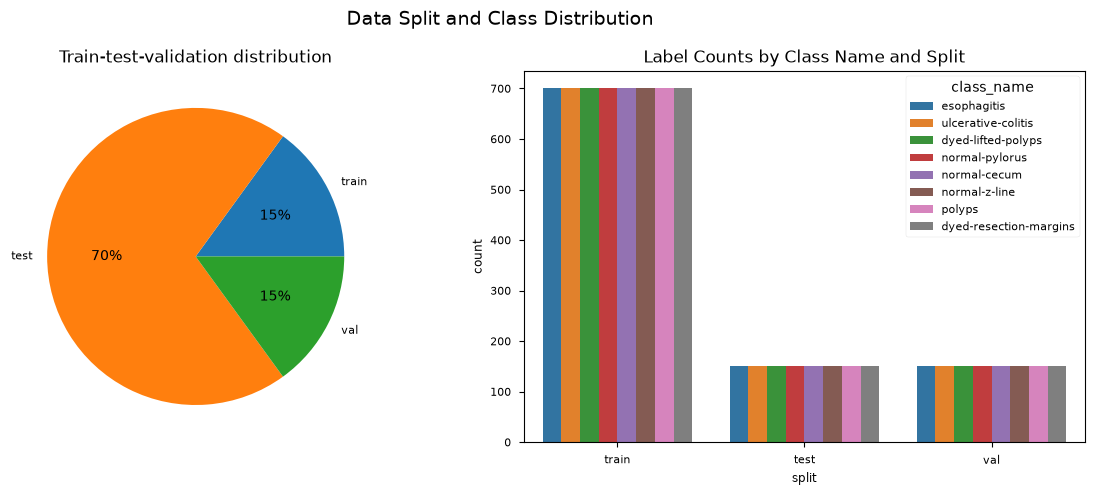

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12,5))
fig.suptitle('Data Split and Class Distribution', fontsize=14)

data = df.groupby('split').sum()
axs[0].pie(data['label'], labels=names, autopct='%.0f%%')
axs[0].set_title('Train-test-validation distribution', fontsize=12)
axs[1] = sns.countplot(data=df, x='split', hue='class_name')
axs[1].set_title('Label Counts by Class Name and Split', fontsize=12)

plt.tight_layout()
plt.savefig("DataSplit_ClassDistribution.svg",transparent=True, dpi= 300, format='svg')
plt.show()

### Model architectures and parameter counts

In [9]:
from models import build_model

MODEL_CHECKPOINTS = {
    "small_cnn": CHECKPOINT_DIR / "small_cnn_best.pth",
    "resnet18": CHECKPOINT_DIR / "resnet18_best.pth",
    "vit_b_16": CHECKPOINT_DIR / "vit_b_16_best.pth",
    "efficientnet_b0": CHECKPOINT_DIR / "efficientnet_b0_best.pth",
    "alexnet": CHECKPOINT_DIR / "alexnet_best.pth",
    "efficientnet_b0_scratch": CHECKPOINT_DIR / "efficientnet_b0_scratch_best.pth",
}

for key, path in MODEL_CHECKPOINTS.items():
    print(key, path)

small_cnn D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\small_cnn_best.pth
resnet18 D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\resnet18_best.pth
vit_b_16 D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\vit_b_16_best.pth
efficientnet_b0 D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\efficientnet_b0_best.pth
alexnet D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\alexnet_best.pth
efficientnet_b0_scratch D:\Documentos\UP\MIACD\DeepLearning_Medical_Image_Analysis\checkpoints\efficientnet_b0_scratch_best.pth


### Train results

| model           | test_samples | accuracy | macro_f1 | macro_specificity | mcc      | inference_seconds | ms_per_image | checkpoint_epoch | validation_macro_f1 |
| --------------- | ------------ | -------- | -------- | ----------------- | -------- | ----------------- | ------------ | ---------------- | ------------------- |
| vit_b_16        | 1200         | 0.901667 | 0.901615 | 0.985952          | 0.887702 | 34.09071          | 28.40893     | 7                | 0.902163            |
| efficientnet_b0 | 1200         | 0.888333 | 0.888015 | 0.984048          | 0.872722 | 21.92969          | 18.27475     | 9                | 0.890066            |
| small_cnn       | 1200         | 0.860833 | 0.860174 | 0.980119          | 0.841718 | 26.22777          | 21.85648     | 33               | 0.839722            |
| resnet18        | 1200         | 0.86     | 0.85979  | 0.98              | 0.840592 | 24.09317          | 20.07764     | 10               | 0.868076            |
| alexnet         | 1200         | 0.8225   | 0.821075 | 0.974643          | 0.797675 | 18.77412          | 15.6451      | 8                | 0.804682            |